In [1]:
# Data handling
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
from pathlib import Path

# Load dataset
dataset_path = Path.cwd().parent / "Datasets" / "churn-bigml-80.csv"

df = pd.read_csv(dataset_path)

# Display first five rows
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
# Check dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (2666, 20)

Column names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes    

In [4]:
# Separate input features and target variable
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2666, 19)
Target shape: (2666,)


In [5]:
# Identify numerical and categorical columns
categorical_columns = X.select_dtypes(include=["str"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["str"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)

Categorical columns: ['State', 'International plan', 'Voice mail plan']

Numerical columns: ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


In [6]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2132, 19)
Testing features: (534, 19)
Training target: (2132,)
Testing target: (534,)


In [7]:
# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
from sklearn.pipeline import Pipeline

# Create the complete machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42))
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [9]:
# Train the Random Forest model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
# Predict customer churn on testing data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("\nFirst 10 actual values:")
print(y_test[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

Predictions completed successfully!

First 10 actual values:
[False, False, False, False, False, False, False, False, False, False]

First 10 predicted values:
[False, False, False, False, False, False, False, False, False, False]


In [11]:
# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation:")
print("-----------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Model Evaluation:
-----------------
Accuracy: 0.9400749063670412
Precision: 1.0
Recall: 0.5897435897435898
F1 Score: 0.7419354838709677


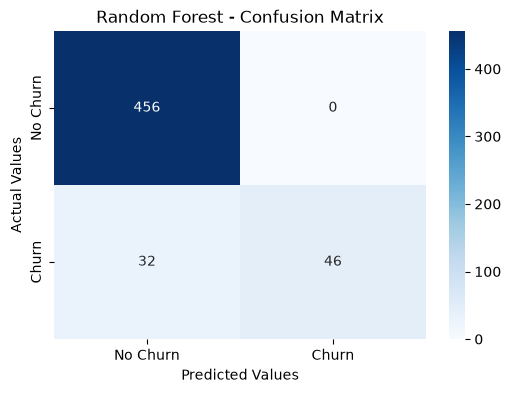

In [12]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [13]:
# Detailed classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.93      1.00      0.97       456
        True       1.00      0.59      0.74        78

    accuracy                           0.94       534
   macro avg       0.97      0.79      0.85       534
weighted avg       0.94      0.94      0.93       534



In [14]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [15]:
# Define hyperparameter combinations
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

print("Hyperparameter grid:")
print(param_grid)

Hyperparameter grid:
{'classifier__n_estimators': [100, 200], 'classifier__max_depth': [None, 10], 'classifier__min_samples_split': [2, 5], 'classifier__min_samples_leaf': [1, 2]}


In [16]:
# Perform hyperparameter tuning using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Hyperparameter tuning completed!


In [17]:
# Display the best hyperparameters and cross-validation score
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Hyperparameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.7789838877878889


In [18]:
# Get the best model
best_model = grid_search.best_estimator_

# Make predictions using the tuned model
y_pred_tuned = best_model.predict(X_test)

# Evaluate tuned model
print("Tuned Random Forest Performance:")
print("--------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

Tuned Random Forest Performance:
--------------------------------
Accuracy: 0.9419475655430711
Precision: 1.0
Recall: 0.6025641025641025
F1 Score: 0.752


In [19]:
# Extract feature importance from the tuned model
feature_importance = best_model.named_steps["classifier"].feature_importances_

# Get feature names after preprocessing
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

                                Feature  Importance
58         remainder__Total day minutes    0.119444
60          remainder__Total day charge    0.118492
70    remainder__Customer service calls    0.105006
63          remainder__Total eve charge    0.054483
61         remainder__Total eve minutes    0.049644
67        remainder__Total intl minutes    0.047378
68          remainder__Total intl calls    0.046236
52  categorical__International plan_Yes    0.045083
51   categorical__International plan_No    0.042100
69         remainder__Total intl charge    0.040071


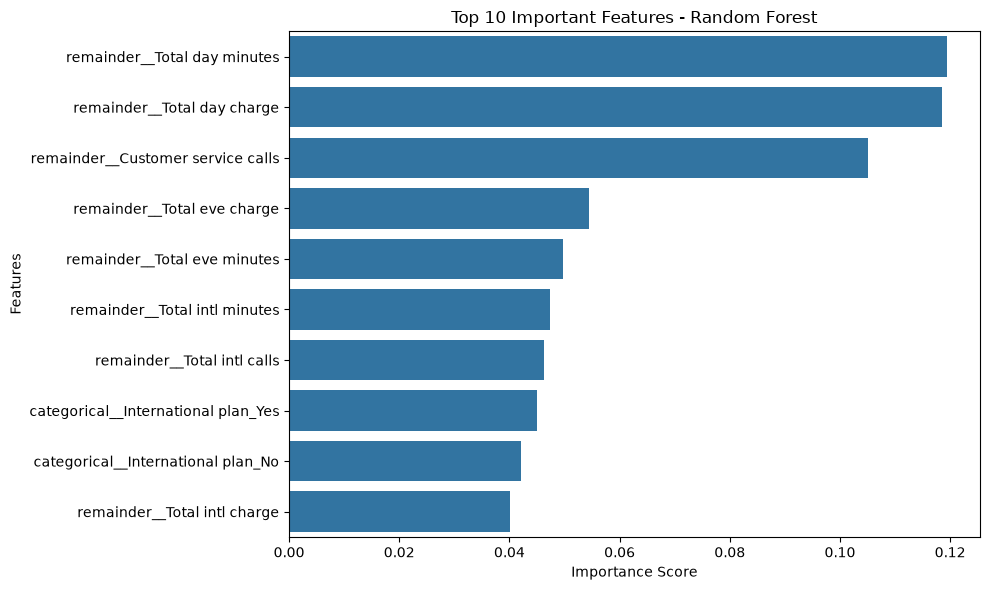

In [20]:
# Visualize top 10 important features
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [21]:
# Final model summary
print("RANDOM FOREST CLASSIFICATION - FINAL SUMMARY")
print("--------------------------------------------")

print("Dataset size:", df.shape)
print("Best Parameters:", grid_search.best_params_)
print("Cross-Validation F1 Score:", round(grid_search.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Test Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Test Recall:", round(recall_score(y_test, y_pred_tuned), 4))
print("Test F1 Score:", round(f1_score(y_test, y_pred_tuned), 4))

print("\nTop 5 Important Features:")
print(importance_df.head(5).to_string(index=False))

RANDOM FOREST CLASSIFICATION - FINAL SUMMARY
--------------------------------------------
Dataset size: (2666, 20)
Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Cross-Validation F1 Score: 0.779
Test Accuracy: 0.9419
Test Precision: 1.0
Test Recall: 0.6026
Test F1 Score: 0.752

Top 5 Important Features:
                          Feature  Importance
     remainder__Total day minutes    0.119444
      remainder__Total day charge    0.118492
remainder__Customer service calls    0.105006
      remainder__Total eve charge    0.054483
     remainder__Total eve minutes    0.049644


## Conclusion

In this task, I developed a Random Forest Classification model to predict customer churn using Python and Scikit-learn.

The following steps were performed:

1. Loaded and explored the customer churn dataset.
2. Identified numerical and categorical features.
3. Split the dataset into training and testing sets.
4. Applied One-Hot Encoding to categorical features.
5. Built and trained a Random Forest Classifier.
6. Evaluated the model using accuracy, precision, recall, F1-score, confusion matrix, and classification report.
7. Performed hyperparameter tuning using GridSearchCV with 5-fold cross-validation.
8. Identified and visualized the most important features affecting customer churn.

The task helped me understand ensemble learning, Random Forest classification, cross-validation, hyperparameter optimization, and feature importance.